<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AMLEXP14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

marketing_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/marketing_campaign_cleaned.csv")

target_marketing = "Response"   # Modify if required

# Feature engineering
if {"Kidhome", "Teenhome"}.issubset(marketing_df.columns):
    marketing_df["TotalChildren"] = (
        marketing_df["Kidhome"] + marketing_df["Teenhome"]
    )

spending_columns = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]

available_spending = [
    column for column in spending_columns
    if column in marketing_df.columns
]

if available_spending:
    marketing_df["TotalSpending"] = marketing_df[
        available_spending
    ].sum(axis=1)

purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

available_purchases = [
    column for column in purchase_columns
    if column in marketing_df.columns
]

if available_purchases:
    marketing_df["TotalPurchases"] = marketing_df[
        available_purchases
    ].sum(axis=1)

marketing_df = marketing_df.dropna(subset=[target_marketing])

X = marketing_df.drop(target_marketing, axis=1)
y = marketing_df[target_marketing]

# Convert target to numeric if it is text
if y.dtype == "object":
    y = y.astype("category").cat.codes
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])
preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
marketing_predictions = {}
for name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    model.fit(X_train, y_train)
    marketing_predictions[name] = model.predict(X_test)

    print(name, "training completed")

Logistic Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


,Model,Accuracy,Precision,Recall,F1 Score
3,Gradient Boosting,0.879464,0.867603,0.879464,0.855099
0,Logistic Regression,0.841518,0.878048,0.841518,0.854114
2,Random Forest,0.875000,0.865431,0.875000,0.843820
1,Decision Tree,0.814732,0.852164,0.814732,0.828844


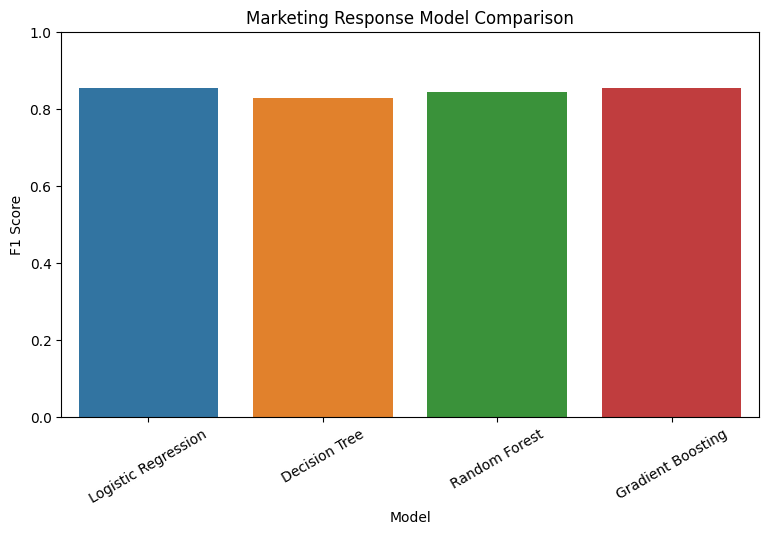

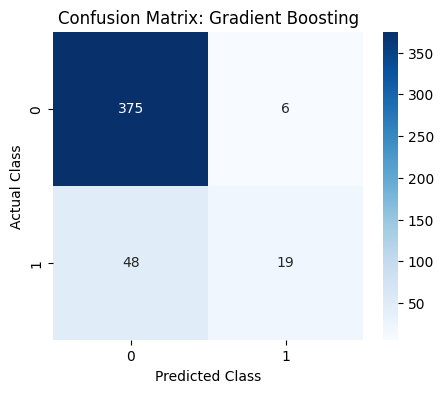

Best model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.89      0.98      0.93       381
           1       0.76      0.28      0.41        67

    accuracy                           0.88       448
   macro avg       0.82      0.63      0.67       448
weighted avg       0.87      0.88      0.86       448



In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

marketing_results = []

for name, prediction in marketing_predictions.items():
    marketing_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(
            y_test, prediction, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, prediction, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, prediction, average="weighted", zero_division=0
        )
    })

marketing_results_df = pd.DataFrame(marketing_results)
display(marketing_results_df.sort_values(
    "F1 Score",
    ascending=False
))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=marketing_results_df,
    x="Model",
    y="F1 Score",
    hue="Model",
    legend=False
)
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.title("Marketing Response Model Comparison")
plt.show()

# Confusion matrix of the best model
best_marketing_name = marketing_results_df.loc[
    marketing_results_df["F1 Score"].idxmax(),
    "Model"
]
best_prediction = marketing_predictions[best_marketing_name]
cm = confusion_matrix(y_test, best_prediction)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(f"Confusion Matrix: {best_marketing_name}")
plt.show()
print("Best model:", best_marketing_name)
print(classification_report(
    y_test,
    best_prediction,
    zero_division=0
))